# 2. QQQ DAILY RSI(2) MEAN REVERSION - IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK
## SYSTEMATIC TRADING APPROACH FOLLOWING ALPHACA FRAMEWORK

This notebook executes in-sample parameter sensitivity analysis on the **Alphaca RSI(2) Mean Reversion** strategy on QQQ daily bars.

### STRICT METHODOLOGICAL CONSTRAINT:
> **IN-SAMPLE DATA ONLY**: Out-of-sample data is strictly excluded from this notebook. All grids and sensitivity evaluations are performed on the in-sample portion (1999-12-21 through 2018-09-14).

### OBJECTIVES:
1. **Plateau vs. Cliff Validation**: Verify that the hypothesis-chosen parameters (`RSI=between 14 and 20, SMA=between 190 and 250`) reside on a wide, stable parameter plateau rather than an over-optimized isolated peak.
2. **Anti-Cliff Check**: Ensure moving one step away in any parameter direction does not cause performance to collapse (drop $\le 30\%$).

### STRATEGY PARAMETERS

In [1]:
VARIANT = "base_nasdaq" 

## 1. IMPORTS AND IN-SAMPLE DATA SETUP

In [2]:
import os
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Walk up from start (cwd by default) and return the first folder that contains `name`."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR    = find_upwards('variants')                  # edge folder, any name
utils_path  = str(find_upwards('utils') / 'utils')      # research_development/utils
engine_path = str(EDGE_DIR)
engine_dir  = str(EDGE_DIR / 'rsi2_engine')

for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from robustness import grid_search, plateau_check, plot_grid
import rsi2_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # resets ENGINE_DEFAULTS: nothing leaks between variants

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), \
    f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
SMA_LEN    = cfg["params"]["sma_len"]
RSI_THR    = cfg["params"]["rsi_thr"]
EXIT_MODE  = cfg["params"]["exit_mode"]
SLIP_BPS   = cfg["params"]["slip_bps_per_side"]
RSI_VALUES = cfg["grid"]["rsi_values"]
SMA_VALUES = cfg["grid"]["sma_values"]

print("Imports complete.")
print(f"Variant: {cfg['id']} | {TICKER} | candidate RSI<{RSI_THR:g}, SMA({SMA_LEN}) | exit={EXIT_MODE} | {SLIP_BPS:g} bps/side")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")

df_raw = eng.load_data(TICKER, start=DATA_START)

common_start = eng.prepare(df_raw, sma_len=max(SMA_VALUES)).index[0]

df_full_prep = eng.prepare(df_raw, sma_len=SMA_LEN)
df_full_prep = df_full_prep[df_full_prep.index >= common_start]
is_end_date = df_full_prep.index[df_full_prep.index < OOS_START][-1]
n_is = int((df_full_prep.index <= is_end_date).sum())

print(f"Strict In-Sample Range: {df_full_prep.index.min().strftime('%Y-%m-%d')} to {is_end_date.strftime('%Y-%m-%d')}")
print(f"Total In-Sample Bars: {n_is:,}")

Imports complete.
Variant: RSI2.nasdaq.base | ^NDX | candidate RSI<20, SMA(230) | exit=2green | 5 bps/side
Data source: yahoo | swap: 0 bps/night
Strict In-Sample Range: 2000-02-25 to 2018-09-21
Total In-Sample Bars: 4,674


## 2. 2D PARAMETER GRID (RSI THRESHOLD X SMA PERIOD)

In [3]:
rsi_values = RSI_VALUES
sma_values = SMA_VALUES

# Precompute prepared data for each SMA length on the In-Sample slice only,
# all aligned to the exact same start and end dates.
is_dfs = {}
for sma in sma_values:
    prep = eng.prepare(df_raw, sma_len=sma)
    prep = prep[prep.index >= common_start]
    is_dfs[sma] = prep[prep.index <= is_end_date].copy()

assert len({(d.index[0], d.index[-1], len(d)) for d in is_dfs.values()}) == 1, \
    "All SMA series must use the same date window."

def evaluate(rsi, sma):
    d = is_dfs[sma]
    trades = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
    if len(trades) == 0:
        return (0.0, 0)
    p = trades['pnl'].values
    g, l = p[p > 0].sum(), -p[p < 0].sum()
    pf = float(g / l) if l > 0 else np.inf
    return (pf, int(len(trades)))

pf_grid, n_grid = grid_search(evaluate, rsi_values, sma_values)

print("=" * 70)
print("IN-SAMPLE PROFIT FACTOR GRID (RSI x SMA)")
print("=" * 70)
display(pf_grid.round(3))

print("\n" + "=" * 70)
print("IN-SAMPLE TRADE COUNT GRID (N)")
print("=" * 70)
display(n_grid.astype(int))

IN-SAMPLE PROFIT FACTOR GRID (RSI x SMA)


,140,170,200,230,260,290
5,3.045,3.240,2.510,2.797,2.675,3.100
10,1.763,1.735,1.746,1.969,1.991,1.989
15,1.586,1.609,1.660,1.708,1.765,1.801
20,1.393,1.518,1.564,1.712,1.645,1.658
25,1.257,1.300,1.335,1.428,1.377,1.402
29,1.238,1.196,1.297,1.386,1.357,1.366
30,1.168,1.138,1.252,1.352,1.320,1.334



IN-SAMPLE TRADE COUNT GRID (N)


,140,170,200,230,260,290
5,61,62,70,73,74,76
10,127,136,137,142,147,146
15,185,186,184,187,195,197
20,226,229,228,229,235,236
25,259,258,257,255,262,264
29,279,277,274,275,284,285
30,286,284,281,281,290,291


## 3. PARAMETER PLATEAU & ANTI-CLIFF VERIFICATION

PLATEAU DIAGNOSTIC RESULTS - Configured (20, 230):
  center_pf                : 1.7119436900641982
  plateau                  : True
  worst_neighbor_drop_pct  : 22.010080440609315
  anticliff                : True
  passed                   : True
  pct_cells_pf_ok          : 0.8333333333333334
  best_cell                : (np.int64(5), np.int64(170))
  best_pf                  : 3.239598271174266
  edge_of_grid             : False
Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : PASSED
Anti-Cliff Condition (Worst neighbor drop <= 30%)        : PASSED
Overall Plateau Verdict                                   : PASSED


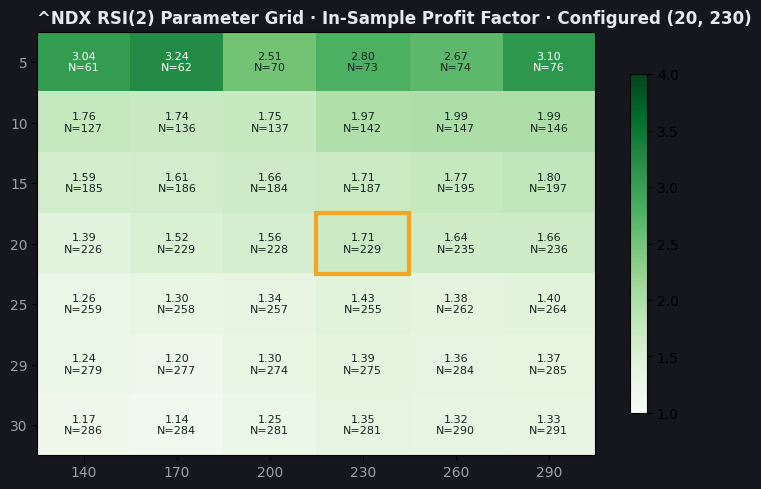

PLATEAU DIAGNOSTIC RESULTS - Baseline (15, 200):
  center_pf                : 1.6596851396875691
  plateau                  : True
  worst_neighbor_drop_pct  : 8.515023203385253
  anticliff                : True
  passed                   : True
  pct_cells_pf_ok          : 0.8333333333333334
  best_cell                : (np.int64(5), np.int64(170))
  best_pf                  : 3.239598271174266
  edge_of_grid             : False
Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : PASSED
Anti-Cliff Condition (Worst neighbor drop <= 30%)        : PASSED
Overall Plateau Verdict                                   : PASSED


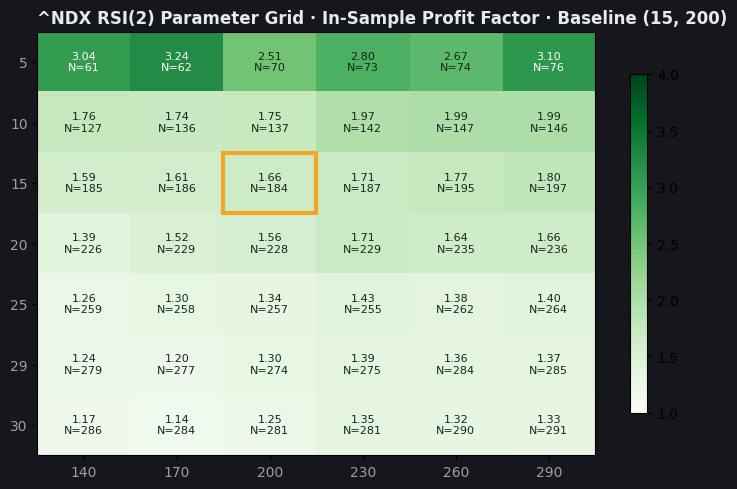

TEXT DUMP · 2D GRID (Two Green Candles · 5 bps) | * = configured, # = baseline

Profit Factor (rows = RSI threshold, cols = SMA length):
           140   170    200    230   260   290
RSI<\SMA                                      
5         3.04  3.24   2.51   2.80  2.67  3.10
10        1.76  1.74   1.75   1.97  1.99  1.99
15        1.59  1.61  1.66#   1.71  1.77  1.80
20        1.39  1.52   1.56  1.71*  1.64  1.66
25        1.26  1.30   1.34   1.43  1.38  1.40
29        1.24  1.20   1.30   1.39  1.36  1.37
30        1.17  1.14   1.25   1.35  1.32  1.33

Trades (N):
          140  170   200   230  260  290
RSI<\SMA                                
5          61   62    70    73   74   76
10        127  136   137   142  147  146
15        185  186  184#   187  195  197
20        226  229   228  229*  235  236
25        259  258   257   255  262  264
29        279  277   274   275  284  285
30        286  284   281   281  290  291


In [12]:
CHOSEN_POINTS = {
    f"Configured ({int(RSI_THR)}, {int(SMA_LEN)})": (int(RSI_THR), int(SMA_LEN)),
}
if (int(RSI_THR), int(SMA_LEN)) != (15, 200):
    CHOSEN_POINTS["Baseline (15, 200)"] = (15, 200)

checks = {}
for label, pt in CHOSEN_POINTS.items():
    check = plateau_check(pf_grid, n_grid, chosen=pt, pf_min=1.3, n_min=30, max_drop_pct=30.0)
    checks[label] = check

    print("=" * 70)
    print(f"PLATEAU DIAGNOSTIC RESULTS - {label}:")
    print("=" * 70)
    for k, v in check.items():
        print(f"  {k:<25}: {v}")
    print("=" * 70)
    print(f"Plateau Condition (3x3 neighborhood >= 1.3 PF & N >= 30) : {'PASSED' if check['plateau'] else 'FAILED'}")
    print(f"Anti-Cliff Condition (Worst neighbor drop <= 30%)        : {'PASSED' if check['anticliff'] else 'FAILED'}")
    print(f"Overall Plateau Verdict                                   : {'PASSED' if check['passed'] else 'FAILED'}")
    print("=" * 70)

    plot_grid(pf_grid, n_grid, chosen=pt,
                title=f"{TICKER} RSI(2) Parameter Grid · In-Sample Profit Factor · {label}",
                vmin=1.0, vmax=4.0)

def grid_to_text(df, marks=None, fmt="{:.2f}"):
    """Grid -> aligned text. marks = {(rsi, sma): '*'} appends a marker to that cell."""
    s = df.astype(float).apply(lambda col: col.map(fmt.format))
    for (r, c), m in (marks or {}).items():
        if r in s.index and c in s.columns:
            s.loc[r, c] = s.loc[r, c] + m
    s.index.name = "RSI<\\SMA"
    return s.to_string()

marks = {pt: ("*" if i == 0 else "#") for i, pt in enumerate(CHOSEN_POINTS.values())}
print("=" * 70)
print("TEXT DUMP · 2D GRID (Two Green Candles · 5 bps) | * = configured, # = baseline")
print("=" * 70)
print("\nProfit Factor (rows = RSI threshold, cols = SMA length):")
print(grid_to_text(pf_grid.replace(np.inf, np.nan), marks))
print("\nTrades (N):")
print(grid_to_text(n_grid, marks, fmt="{:.0f}"))


## 4. 4D MULTI-SCENARIO ROBUSTNESS (3 EXITS X 2 COST LEVELS = 6 GRIDS)

4D MULTI-SCENARIO GRID RESULTS
Total Parameter Combinations Tested : 252
Combinations with PF >= 1.3         : 73.0% (184 / 252)
Combinations with PF >= 1.0         : 100.0% (252 / 252)
Minimum Profit Factor Across Grids  : 1.01
Median Profit Factor Across Grids   : 1.49
Maximum Profit Factor Across Grids  : 3.76
Chosen Config PF (20, 230, 2G, 5bps): 1.712
Percentile of Chosen Configuration  : 67.9%


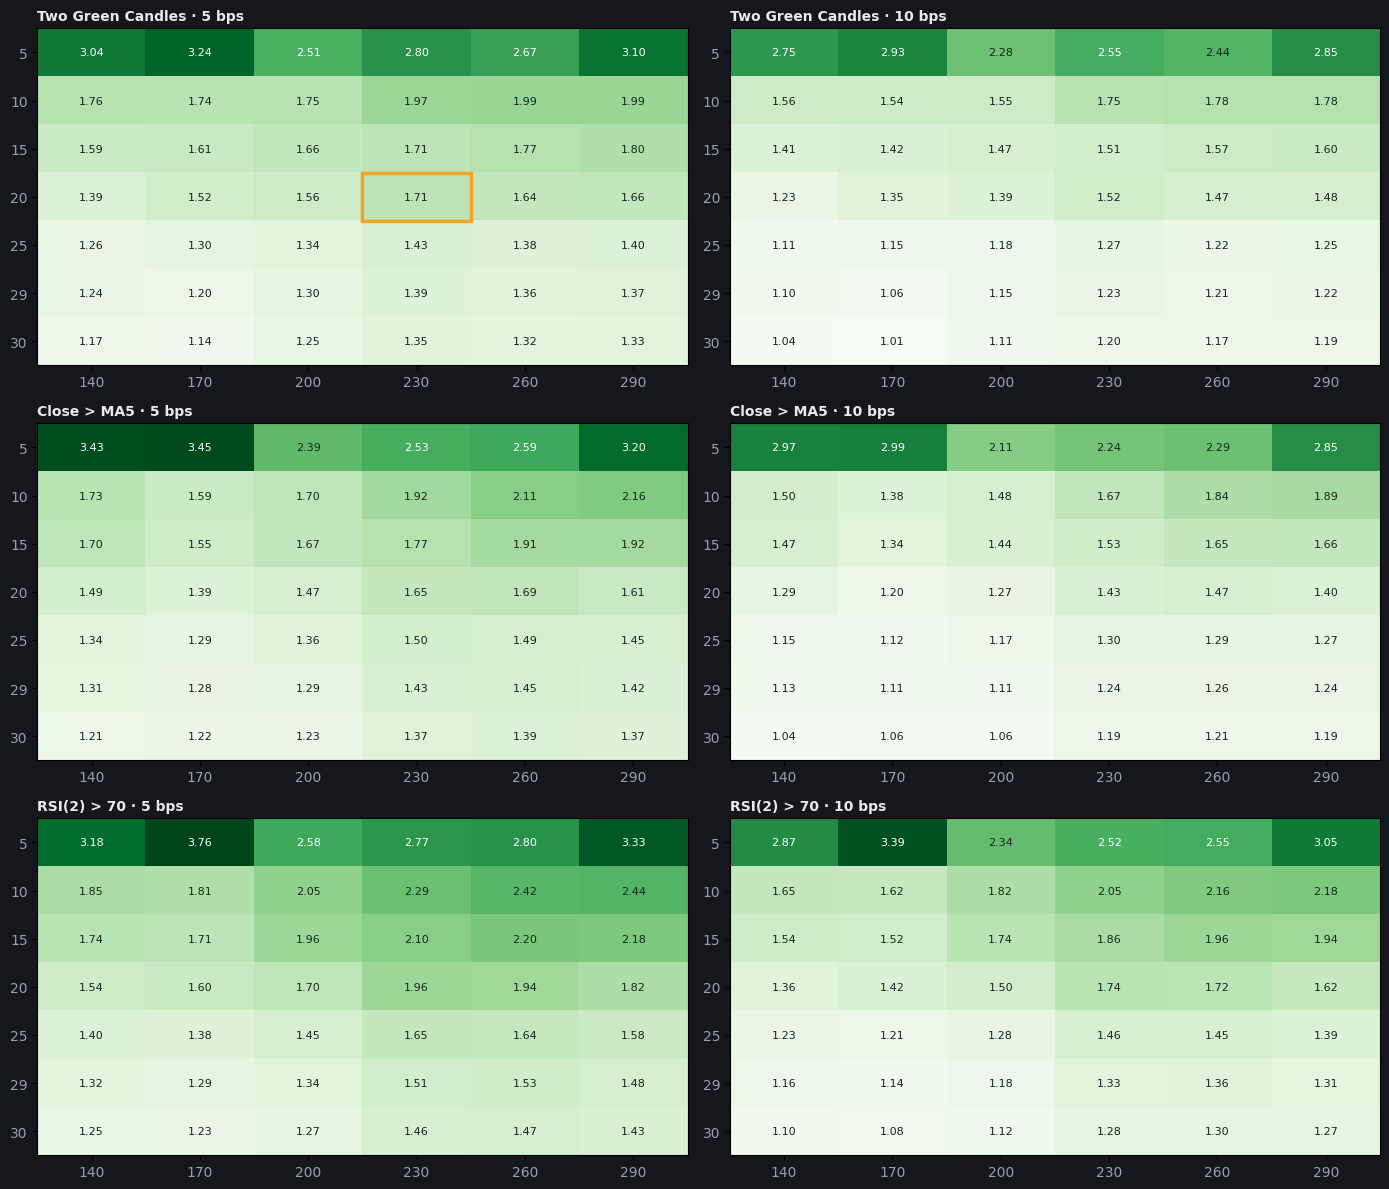

TEXT DUMP · 6 SCENARIOS
                           min  median   max  pct_ge_1_3  pct_ge_1_0
exit              cost                                              
Close > MA5       10 bps  1.04    1.32  2.99       50.00       100.0
                  5 bps   1.21    1.52  3.45       85.71       100.0
RSI(2) > 70       10 bps  1.08    1.51  3.39       73.81       100.0
                  5 bps   1.23    1.70  3.76       90.48       100.0
Two Green Candles 10 bps  1.01    1.40  2.93       54.76       100.0
                  5 bps   1.14    1.57  3.24       83.33       100.0

----------------------------------------------------------------------
Two Green Candles · 5 bps · Profit Factor
           140   170   200    230   260   290
RSI<\SMA                                     
5         3.04  3.24  2.51   2.80  2.67  3.10
10        1.76  1.74  1.75   1.97  1.99  1.99
15        1.59  1.61  1.66   1.71  1.77  1.80
20        1.39  1.52  1.56  1.71*  1.64  1.66
25        1.26  1.30  1.34   1.43 

In [13]:
exits = [('2green', 'Two Green Candles'), ('ma5', 'Close > MA5'), ('rsi70', 'RSI(2) > 70')]
costs = [(5.0, '5 bps'), (10.0, '10 bps')]

all_combos = []
grid_results = {}

for exit_code, exit_label in exits:
    for slip_val, slip_label in costs:
        grid_key = f"{exit_label} · {slip_label}"
        pf_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        n_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=int)
        
        for rsi in rsi_values:
            for sma in sma_values:
                d = is_dfs[sma]
                trades = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=exit_code, slip_bps_per_side=slip_val)
                if len(trades) > 0:
                    p = trades['pnl'].values
                    g, l = p[p > 0].sum(), -p[p < 0].sum()
                    pf = float(g / l) if l > 0 else np.inf
                else:
                    pf = 0.0
                n = len(trades)
                pf_sub.loc[rsi, sma] = pf
                n_sub.loc[rsi, sma] = n
                
                all_combos.append({
                    'exit': exit_label, 'cost': slip_label, 'rsi': rsi, 'sma': sma,
                    'pf': pf, 'n': n
                })
        grid_results[grid_key] = pf_sub

combos_df = pd.DataFrame(all_combos)
pfs = combos_df['pf'].values

pct_pf13 = (pfs >= 1.3).mean() * 100.0
pct_pf10 = (pfs >= 1.0).mean() * 100.0
min_pf = pfs.min()
med_pf = np.median(pfs)
max_pf = pfs.max()

chosen_pf = combos_df.loc[
    (combos_df['exit'] == 'Two Green Candles') &
    (combos_df['cost'] == '5 bps') &
    (combos_df['rsi'] == int(RSI_THR)) &
    (combos_df['sma'] == int(SMA_LEN)), 'pf'
].values[0]

percentile_chosen = (pfs < chosen_pf).mean() * 100.0

print("=" * 70)
print("4D MULTI-SCENARIO GRID RESULTS")
print("=" * 70)
print(f"Total Parameter Combinations Tested : {len(combos_df)}")
print(f"Combinations with PF >= 1.3         : {pct_pf13:.1f}% ({int((pfs >= 1.3).sum())} / {len(combos_df)})")
print(f"Combinations with PF >= 1.0         : {pct_pf10:.1f}% ({int((pfs >= 1.0).sum())} / {len(combos_df)})")
print(f"Minimum Profit Factor Across Grids  : {min_pf:.2f}")
print(f"Median Profit Factor Across Grids   : {med_pf:.2f}")
print(f"Maximum Profit Factor Across Grids  : {max_pf:.2f}")
print(f"Chosen Config PF ({int(RSI_THR)}, {int(SMA_LEN)}, 2G, 5bps): {chosen_pf:.3f}")
print(f"Percentile of Chosen Configuration  : {percentile_chosen:.1f}%")
print("=" * 70)

# Display Grid Comparisons by Exit and Cost
fig, axes = plt.subplots(3, 2, figsize=(14, 12), facecolor='#15171c')
for idx, (title, grid_df) in enumerate(grid_results.items()):
    r, c = idx // 2, idx % 2
    ax = axes[r, c]
    ax.set_facecolor('#1b1e26')
    im = ax.imshow(grid_df.values, cmap='Greens', vmin=1.0, vmax=3.5, aspect='auto')
    ax.set_xticks(range(len(sma_values)))
    ax.set_xticklabels(sma_values, color='#9aa0ab')
    ax.set_yticks(range(len(rsi_values)))
    ax.set_yticklabels(rsi_values, color='#9aa0ab')
    ax.set_title(title, color='#e8e9ec', fontweight='bold', fontsize=10, loc='left')
    for i in range(len(rsi_values)):
        for j in range(len(sma_values)):
            val = grid_df.iloc[i, j]
            ax.text(j, i, f"{val:.2f}", ha='center', va='center', fontsize=8,
                    color='white' if val > 2.5 else '#132620')
    if "Two Green Candles" in title and "5 bps" in title:
        ia, ib = rsi_values.index(int(RSI_THR)), sma_values.index(int(SMA_LEN))
        ax.add_patch(plt.Rectangle((ib - 0.5, ia - 0.5), 1, 1, fill=False, ec='#f5a524', lw=2.5))

plt.tight_layout()
plt.show()

# ---- per-scenario summary ----
print("=" * 70)
print("TEXT DUMP · 6 SCENARIOS")
print("=" * 70)
summ = (combos_df.groupby(["exit", "cost"])["pf"]
        .agg(min="min", median="median", max="max",
             pct_ge_1_3=lambda x: (x >= 1.3).mean() * 100,
             pct_ge_1_0=lambda x: (x >= 1.0).mean() * 100)
        .round(2))
print(summ.to_string())

# ---- full grids per scenario (PF and N) | * = configured point, only in 2G · 5 bps ----
for grid_key, pf_df in grid_results.items():
    exit_label, cost_label = grid_key.split(" · ")
    marks4 = {}
    if exit_label == "Two Green Candles" and cost_label == "5 bps":
        marks4[(int(RSI_THR), int(SMA_LEN))] = "*"
    n_df = (combos_df[(combos_df["exit"] == exit_label) & (combos_df["cost"] == cost_label)]
            .pivot(index="rsi", columns="sma", values="n"))
    print("\n" + "-" * 70)
    print(f"{grid_key} · Profit Factor")
    print(grid_to_text(pf_df.replace(np.inf, np.nan), marks4))
    print(f"\n{grid_key} · Trades (N)")
    print(grid_to_text(n_df, marks4, fmt="{:.0f}"))

In [6]:
for label, (r, s) in CHOSEN_POINTS.items():
    pf_pt = combos_df.loc[
        (combos_df['exit'] == 'Two Green Candles') & (combos_df['cost'] == '5 bps') &
        (combos_df['rsi'] == r) & (combos_df['sma'] == s), 'pf'
    ].values[0]
    print(f"{label:<22}: PF = {pf_pt:.3f} | percentile among {len(combos_df)} combinations = {(pfs < pf_pt).mean()*100:.1f}%")


Configured (20, 230)  : PF = 1.712 | percentile among 252 combinations = 67.9%
Baseline (15, 200)    : PF = 1.660 | percentile among 252 combinations = 63.9%


## 4.5 INTERACTIVE 3D PROFIT FACTOR SURFACE GRAPH

In [11]:
import plotly.graph_objects as go

# ---- extra data for the hover: trades (N) and max drawdown (ATR sizing) per cell ----
n_grids  = {}
dd_grids = {}
for exit_code, exit_label in exits:
    for slip_val, slip_label in costs:
        key = f"{exit_label} · {slip_label}"
        n_sub  = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        dd_sub = pd.DataFrame(index=rsi_values, columns=sma_values, dtype=float)
        for rsi in rsi_values:
            for sma in sma_values:
                d = is_dfs[sma]
                t = eng.run_rsi2_backtest(d, rsi_thr=rsi, sma_len=sma, exit_mode=exit_code,
                                          slip_bps_per_side=slip_val)
                n_sub.loc[rsi, sma] = len(t)
                if len(t) > 0:
                    eq = (1.0 + eng.daily_returns(d, t, sizing="atr")).cumprod()
                    dd_sub.loc[rsi, sma] = 100.0 * float((eq / eq.cummax() - 1.0).min())
        n_grids[key], dd_grids[key] = n_sub, dd_sub

# ---- interactive 3D surface, one button per scenario ----
colorscale = [[0.00, "#b5452f"], [0.25, "#e8a46a"], [0.50, "#f4e79a"],
              [0.75, "#8fd19e"], [1.00, "#2f7d55"]]
keys = list(grid_results.keys())
fig = go.Figure()

for i, key in enumerate(keys):
    pf = grid_results[key].astype(float).replace(np.inf, np.nan)
    cd = np.dstack([n_grids[key].values, dd_grids[key].values])
    fig.add_trace(go.Surface(
        x=list(sma_values), y=list(rsi_values), z=pf.values, customdata=cd,
        colorscale=colorscale, cmin=1.0, cmax=3.0,
        colorbar=dict(title="Profit<br>Factor", len=0.7, x=0.92),
        hovertemplate=("SMA %{x}<br>RSI < %{y}<br>PF %{z:.2f}"
                       "<br>Trades %{customdata[0]:.0f}"
                       "<br>MaxDD %{customdata[1]:.1f}%<extra></extra>"),
        visible=(i == 0)))
    fig.add_trace(go.Scatter3d(
        x=[int(SMA_LEN)], y=[int(RSI_THR)], z=[float(pf.loc[int(RSI_THR), int(SMA_LEN)]) + 0.05],
        mode="markers+text", text=["chosen"], textposition="top center",
        marker=dict(size=6, color="black"), showlegend=False,
        hovertemplate=f"Chosen: RSI < {int(RSI_THR)}, SMA {int(SMA_LEN)}<extra></extra>",
        visible=(i == 0)))

# ~3 px of breathing room on each side of every button label (non-breaking spaces)
PAD = "\u00a0"
buttons = []
for i, key in enumerate(keys):
    vis = [False] * (2 * len(keys))
    vis[2 * i] = vis[2 * i + 1] = True
    buttons.append(dict(label=f"{PAD}{key}{PAD}", method="update", args=[{"visible": vis}]))

fig.update_layout(
    template="plotly_dark", paper_bgcolor="#15171c", height=650,
    title=dict(text=f"{cfg['id']} · In-sample Profit Factor surface (RSI x SMA)", x=0.02),
    scene=dict(
        xaxis_title="SMA length", yaxis_title="RSI threshold", zaxis_title="Profit Factor",
        aspectmode="manual", aspectratio=dict(x=1.5, y=1.0, z=0.7),
        camera=dict(eye=dict(x=1.6, y=1.6, z=0.9), center=dict(x=0, y=0, z=-0.1))),
    updatemenus=[dict(
        type="buttons", direction="right", x=0.0, xanchor="left", y=1.12, yanchor="top", active=0,
        buttons=buttons, bgcolor="#9fb3c8", bordercolor="#4a5160", borderwidth=1,
        pad=dict(l=3, r=3, t=0, b=0),
        font=dict(color="#15171c", size=12))],
    margin=dict(l=0, r=0, t=90, b=0))

fig.show()
fig.write_html(Path(RUN_DIR) / "02_pf_surface.html", include_plotlyjs="cdn")

## 5. CONCLUSION & OPTIMIZATION FINDINGS

In [8]:
print("=" * 70)
print("CONCLUSIONS (computed from notebook results)")
print("=" * 70)
for label, chk in checks.items():
    print(f"{label}: center PF {chk['center_pf']:.3f} | worst neighbor -{chk['worst_neighbor_drop_pct']:.1f}% | "
          f"plateau {'PASS' if chk['plateau'] else 'FAIL'} | anti-cliff {'PASS' if chk['anticliff'] else 'FAIL'} | "
          f"edge of grid: {chk['edge_of_grid']}")
print(f"4D: {pct_pf13:.1f}% of {len(combos_df)} combinations with PF >= 1.3 "
      f"({int((pfs >= 1.3).sum())}/{len(combos_df)}), {pct_pf10:.1f}% with PF >= 1.0, "
      f"min {min_pf:.2f}, median {med_pf:.2f}, max {max_pf:.2f}")


CONCLUSIONS (computed from notebook results)
Configured (20, 230): center PF 1.712 | worst neighbor -22.0% | plateau PASS | anti-cliff PASS | edge of grid: False
Baseline (15, 200): center PF 1.660 | worst neighbor -8.5% | plateau PASS | anti-cliff PASS | edge of grid: False
4D: 73.0% of 252 combinations with PF >= 1.3 (184/252), 100.0% with PF >= 1.0, min 1.01, median 1.49, max 3.76


## 6. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [9]:
pd.DataFrame(pf_grid).to_csv(RUN_DIR / "02_pf_grid.csv")
pd.DataFrame(n_grid).to_csv(RUN_DIR / "02_n_grid.csv")

save_json(cfg, "02_optimization.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params_tested": {"rsi_thr": RSI_THR, "sma_len": SMA_LEN, "exit_mode": EXIT_MODE},
    "is_end_date": str(is_end_date.date()),
    "n_is_bars": int(n_is),
    "plateau_checks": checks,
    "grid_4d": {
        "n_combinations": int(len(combos_df)),
        "pct_pf_ge_1_3": float(pct_pf13),
        "pct_pf_ge_1_0": float(pct_pf10),
        "min_pf": float(min_pf),
        "median_pf": float(med_pf),
        "max_pf": float(max_pf),
        "chosen_pf": float(chosen_pf),
        "chosen_percentile": float(percentile_chosen),
    },
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2/runs/base_nasdaq/02_optimization.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/RSI2/notebooks/RSI2/runs/base_nasdaq/02_optimization.json')

## 7. OPTIMIZATION PARITY

In [10]:
BASE_VARIANT = "base_nasdaq"   # base variant: yaml name without .yaml. In the base/ETF notebooks: None

# Robustness: variant vs base (IN-SAMPLE ONLY).
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)
    rb_all = eng.load_data(cb["instrument"]["ticker"], start=DATA_START, source="yahoo")

    # Same in-sample window as the variant
    base_common = eng.prepare(rb_all, sma_len=max(SMA_VALUES)).index[0]
    if base_common > common_start:
        print(f"WARNING: base data starts later ({base_common:%Y-%m-%d}) than the variant window "
              f"({common_start:%Y-%m-%d}). Grids cover slightly different periods.")
    start_b = max(common_start, base_common)

    is_dfs_b = {}
    for sma in sma_values:
        prep = eng.prepare(rb_all, sma_len=sma)
        is_dfs_b[sma] = prep[(prep.index >= start_b) & (prep.index <= is_end_date)].copy()

    def evaluate_base(rsi, sma):
        t = eng.run_rsi2_backtest(is_dfs_b[sma], rsi_thr=rsi, sma_len=sma, exit_mode=EXIT_MODE,
                                  slip_bps_per_side=SLIP_BPS, financing_bps_per_night=0.0)
        if len(t) == 0:
            return (0.0, 0)
        p = t["pnl"].values
        g, l = p[p > 0].sum(), -p[p < 0].sum()
        return (float(g / l) if l > 0 else np.inf, int(len(t)))

    pf_b, n_b = grid_search(evaluate_base, rsi_values, sma_values)

    pf_v = pf_grid.replace(np.inf, np.nan).astype(float)
    pf_bc = pf_b.replace(np.inf, np.nan).astype(float)

    # 1) Grid-level comparison
    print("=" * 70)
    print(f"ROBUSTNESS: VARIANT ({cfg['id']}) vs BASE ({cb['id']}) | IN-SAMPLE")
    print("=" * 70)
    print("PF ratio variant/base per cell (1.00 = identical):")
    display((pf_v / pf_bc).round(3))

    both = pd.concat([pf_v.stack(), pf_bc.stack()], axis=1, keys=["v", "b"]).dropna()
    print(f"\nGrid correlation (PF, {len(both)} cells): {both['v'].corr(both['b']):.3f}")
    print(f"Median PF  variant/base: {both['v'].median():.3f} / {both['b'].median():.3f}")
    print(f"Cells PF >= 1.3 variant/base: {(both['v'] >= 1.3).sum()} / {(both['b'] >= 1.3).sum()} of {len(both)}")
    print(f"Cells PF >= 1.0 variant/base: {(both['v'] >= 1.0).sum()} / {(both['b'] >= 1.0).sum()} of {len(both)}")

    # 2) Plateau / anti-cliff on both grids, same chosen points as section 3
    print("\n" + "-" * 70)
    print(f"{'point':<22}{'':<10}{'center PF':>10}{'worst nb drop':>15}{'plateau':>9}{'anti-cliff':>12}")
    for label, pt in CHOSEN_POINTS.items():
        for name, g, n in (("variant", pf_grid, n_grid), ("base", pf_b, n_b)):
            c = plateau_check(g, n, chosen=pt, pf_min=1.3, n_min=30, max_drop_pct=30.0)
            print(f"{label:<22}{name:<10}{c['center_pf']:>10.3f}{c['worst_neighbor_drop_pct']:>14.1f}%"
                  f"{'PASS' if c['plateau'] else 'FAIL':>9}{'PASS' if c['anticliff'] else 'FAIL':>12}")
else:
    print("BASE_VARIANT is None: nothing to compare.")

ROBUSTNESS: VARIANT (RSI2.nasdaq.base) vs BASE (RSI2.nasdaq.base) | IN-SAMPLE
PF ratio variant/base per cell (1.00 = identical):


,140,170,200,230,260,290
5,1.0,1.0,1.0,1.0,1.0,1.0
10,1.0,1.0,1.0,1.0,1.0,1.0
15,1.0,1.0,1.0,1.0,1.0,1.0
20,1.0,1.0,1.0,1.0,1.0,1.0
25,1.0,1.0,1.0,1.0,1.0,1.0
29,1.0,1.0,1.0,1.0,1.0,1.0
30,1.0,1.0,1.0,1.0,1.0,1.0



Grid correlation (PF, 42 cells): 1.000
Median PF  variant/base: 1.575 / 1.575
Cells PF >= 1.3 variant/base: 35 / 35 of 42
Cells PF >= 1.0 variant/base: 42 / 42 of 42

----------------------------------------------------------------------
point                            center PF  worst nb drop  plateau  anti-cliff
Configured (20, 230)  variant        1.712          22.0%     PASS        PASS
Configured (20, 230)  base           1.712          22.0%     PASS        PASS
Baseline (15, 200)    variant        1.660           8.5%     PASS        PASS
Baseline (15, 200)    base           1.660           8.5%     PASS        PASS
